# VQE + QSNN con dos neuronas Alpha de salida

Esta variante conserva la arquitectura spiking de dos capas del QSNN original: una capa oculta Alpha de 64 neuronas y una capa de salida Alpha de dos neuronas (fase 0 y fase 1). No usa una ruta continua paralela. La QSNN produce dos trenes binarios de spikes; sus tasas se convierten en logits de fase y `softmax` da el score de fase 1. Se elevó el número de pasos y la escala de logits para que el clasificador pueda acercar sus scores a 0 y 1 cuando aprenda una diferencia clara entre ambas salidas. No se fuerza monotonía, suavidad ni valores extremos: la curva sigue siendo la predicción directa del modelo.

El entrenamiento usa `CrossEntropyLoss` con las etiquetas de fase. La escala de logits se fija como hiperparámetro antes del entrenamiento; CrossEntropy la ve durante el aprendizaje. Esta escala no ordena ni suaviza los puntos y no garantiza saturación: los extremos dependen de que la QSNN aprenda una diferencia suficiente entre las tasas de sus dos neuronas de salida.

Los estados VQE de 10 qubits se cargan del archivo existente en `data/`; no se vuelve a optimizar el VQE. La QSNN recibe las probabilidades de medición $|c_k|^2$. Las etiquetas se usan solo como objetivos de entrenamiento, nunca como entradas.

## 1. Configuración

Se usan 100 estados VQE de 10 qubits y un ansatz checkerboard de cuatro capas. La QSNN mantiene dos capas Alpha, con 64 neuronas ocultas y dos salidas Alpha. Se usan 200 pasos temporales; cada tasa de salida tiene resolución de $1/200=0.005$. No se fuerza ninguna forma sobre la curva.

In [10]:
from pathlib import Path
import copy
import json
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from scipy.optimize import minimize
from scipy.sparse.linalg import eigsh
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix
)

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, SparsePauliOp

# --- Modelo y datos ---
N_QUBITS = 10
J = 1.0
H_MIN, H_MAX = 0.0, 2.0 * J
N_H = 100
LAYERS = 4
RANDOM_SEED = 42

# --- VQE: se mantienen L-BFGS-B y los dos barridos ---
MAXITER = 300
TOL = 1e-6
FINITE_DIFF_EPS = 1e-6

# --- QSNN ---
NUM_HIDDEN = 64
NUM_STEPS = 200
NUM_EPOCHS = 300
BATCH_SIZE = 8
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 5e-5
RATE_LOGIT_SCALE = 100.0
PATIENCE = 45
THRESHOLD = 0.75
T1 = 60.0
H_C = J

DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


def set_seed(seed=RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Qubits={N_QUBITS} | h/J ∈ [{H_MIN/J:.1f}, {H_MAX/J:.1f}] | N_h={N_H} | layers={LAYERS}")
print(f"QSNN: hidden={NUM_HIDDEN}, steps={NUM_STEPS}, epochs≤{NUM_EPOCHS}, device={device}")

Qubits=10 | h/J ∈ [0.0, 2.0] | N_h=100 | layers=4
QSNN: hidden=64, steps=200, epochs≤300, device=cpu


## 2. Hamiltoniano y ansatz checkerboard

El Hamiltoniano usado es

$$
H(h)=-J\sum_i Z_iZ_{i+1}-h\sum_iX_i,
\qquad Z_{N}=Z_0.
$$

El ansatz conserva bloques de cinco parámetros \(R_x\otimes R_x\), \(R_{zz}\), \(R_z\otimes R_z\). Las parejas de cada capa no comparten qubits; el generador de emparejamientos incluye todos los enlaces del anillo.

In [11]:
def build_ising_hamiltonian(n_qubits, coupling, h):
    terms = []
    for i in range(n_qubits):
        op = ["I"] * n_qubits
        op[i] = "Z"
        op[(i + 1) % n_qubits] = "Z"
        terms.append(("".join(op), -coupling))
    for i in range(n_qubits):
        op = ["I"] * n_qubits
        op[i] = "X"
        terms.append(("".join(op), -h))
    return SparsePauliOp.from_list(terms).simplify()


def checkerboard_matchings(n_qubits):
    edges = [(i, (i + 1) % n_qubits) for i in range(n_qubits)]
    remaining = edges.copy()
    matchings = []
    while remaining:
        layer, used, rest = [], set(), []
        for q1, q2 in remaining:
            if q1 not in used and q2 not in used:
                layer.append((q1, q2))
                used.update((q1, q2))
            else:
                rest.append((q1, q2))
        matchings.append(layer)
        remaining = rest
    return matchings


def build_checkerboard_ansatz(n_qubits, layers=4):
    qc = QuantumCircuit(n_qubits)
    matchings = checkerboard_matchings(n_qubits)
    pairings = [matchings[layer % len(matchings)] for layer in range(layers)]
    parameter_count = 5 * sum(len(layer) for layer in pairings)
    theta = ParameterVector("theta", parameter_count)
    k = 0
    for layer in pairings:
        for q1, q2 in layer:
            qc.rx(theta[k], q1)
            qc.rx(theta[k + 1], q2)
            qc.rzz(theta[k + 2], q1, q2)
            qc.rz(theta[k + 3], q1)
            qc.rz(theta[k + 4], q2)
            k += 5
    return qc, theta


ansatz, theta_params = build_checkerboard_ansatz(N_QUBITS, LAYERS)
print(f"Enlaces por capa: {[len(layer) for layer in checkerboard_matchings(N_QUBITS)]}")
print(f"Parámetros variacionales: {len(theta_params)}")
print(f"Profundidad del circuito (operaciones): {ansatz.size()}")

Enlaces por capa: [5, 5]
Parámetros variacionales: 100
Profundidad del circuito (operaciones): 100


## 3. Energía, optimización y barrido doble

Se conserva el procedimiento del artículo: cada punto usa como inicialización la solución del punto anterior; después se repite el barrido en sentido inverso y se escoge, para cada \(h\), el estado con menor energía. Se endurece la tolerancia y se quita la opción `disp` que generaba una advertencia de SciPy.

La energía exacta se obtiene con el Hamiltoniano disperso cuando la versión de Qiskit lo permite; si no, se usa la matriz densa como respaldo.

In [12]:
def state_and_energy(ansatz, values, hamiltonian):
    bound = ansatz.assign_parameters(values)
    state = Statevector.from_instruction(bound)
    energy = float(np.real(state.expectation_value(hamiltonian)))
    return state, energy


def objective(values, ansatz, hamiltonian):
    return state_and_energy(ansatz, values, hamiltonian)[1]


def exact_ground_energy(hamiltonian):
    try:
        matrix = hamiltonian.to_matrix(sparse=True)
        return float(np.real(eigsh(matrix, k=1, which="SA", return_eigenvectors=False, tol=1e-9)[0]))
    except (TypeError, ValueError, AttributeError):
        return float(np.real(np.linalg.eigvalsh(hamiltonian.to_matrix())[0]))


def run_vqe_sweep(h_list, direction, ansatz, theta_params, rng):
    sweep = {"states": [], "energies": [], "params": [], "success": [], "iterations": [], "messages": []}
    previous = None
    start = time.time()
    print(f"\nBarrido {direction.upper()}: {len(h_list)} puntos")

    for idx, h in enumerate(h_list):
        hamiltonian = build_ising_hamiltonian(N_QUBITS, J, float(h))
        x0 = rng.uniform(-0.1, 0.1, len(theta_params)) if previous is None else previous.copy()
        result = minimize(
            objective, x0, args=(ansatz, hamiltonian), method="L-BFGS-B",
            options={
                "maxiter": MAXITER, "ftol": TOL, "gtol":TOL,
                "eps": FINITE_DIFF_EPS, "maxls": 30
            }
        )
        previous = result.x.copy()
        state, energy = state_and_energy(ansatz, result.x, hamiltonian)
        state_data = np.asarray(state.data, dtype=np.complex128)
        state_data /= np.linalg.norm(state_data)

        sweep["states"].append(state_data)
        sweep["energies"].append(energy)
        sweep["params"].append(result.x.copy())
        sweep["success"].append(bool(result.success))
        sweep["iterations"].append(int(result.nit))
        sweep["messages"].append(str(result.message))

        if idx % 10 == 0 or idx == len(h_list) - 1:
            print(f"  {idx+1:3d}/{len(h_list)} | h/J={h/J:.4f} | E={energy:.8f} | iter={result.nit} | success={result.success}")

    print(f"Tiempo {direction}: {time.time()-start:.1f} s")
    return {key: np.asarray(value) for key, value in sweep.items()}


Estados VQE cargados: (100, 1024) desde data\vqe_checkerboard_states_10qubits.npz
Error energético medio: 0.035685 | máximo: 0.15249
Suma de probabilidades por estado: [1.0000000000, 1.0000000000]


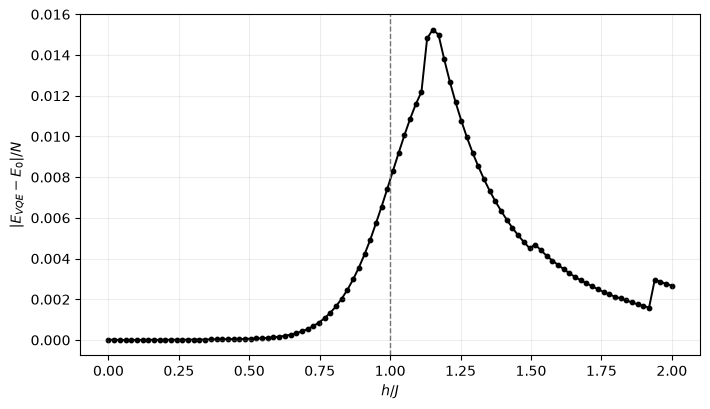

In [13]:
# Reutilizamos la corrida VQE ya guardada; no volvemos a optimizar sus 200 evaluaciones.
vqe_file = DATA_DIR / f"vqe_checkerboard_states_{N_QUBITS}qubits.npz"
if not vqe_file.exists():
    raise FileNotFoundError(
        f"No existe {vqe_file}. Copia aquí el archivo VQE de 10 qubits generado previamente."
    )
with np.load(vqe_file) as saved:
    h_values = np.asarray(saved["h_values"], dtype=float)
    states = np.asarray(saved["states"], dtype=np.complex128)
    energies = np.asarray(saved["energies"], dtype=float)
    exact_energies = np.asarray(saved["exact_energies"], dtype=float)
    energy_errors = np.asarray(saved["energy_errors"], dtype=float)
    probabilities = np.asarray(saved["probabilities"], dtype=float)

if states.shape != (N_H, 2**N_QUBITS):
    raise ValueError(f"Dimensiones incompatibles: {states.shape}; se esperaba {(N_H, 2**N_QUBITS)}")
print(f"Estados VQE cargados: {states.shape} desde {vqe_file}")
print(f"Error energético medio: {energy_errors.mean():.6g} | máximo: {energy_errors.max():.6g}")
print(f"Suma de probabilidades por estado: [{probabilities.sum(axis=1).min():.10f}, {probabilities.sum(axis=1).max():.10f}]")

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(h_values/J, energy_errors/N_QUBITS, color="black", linewidth=1.4)
ax.scatter(h_values/J, energy_errors/N_QUBITS, color="black", s=10)
ax.axvline(H_C/J, color="0.45", linestyle="--", linewidth=1)
ax.set(xlabel=r"$h/J$", ylabel=r"$|E_{VQE}-E_0|/N$")
ax.grid(alpha=0.22)
fig.tight_layout()
plt.show()


## 4. De los estados VQE a la entrada de la QSNN

Cada vector de estado se convierte en probabilidades $x_k=|c_k|^2$. La QSNN recibe filas de 1024 probabilidades. Las etiquetas binarias identifican la fase: $0$ para $h/J<1$ y $1$ para $h/J\geq1$. Se reserva test antes de entrenar; las etiquetas nunca se concatenan a la entrada.

In [14]:
vqe_file = DATA_DIR / f"vqe_checkerboard_states_{N_QUBITS}qubits.npz"
if not vqe_file.exists():
    raise FileNotFoundError(f"No existe {vqe_file}. Ejecuta primero las celdas del VQE.")

with np.load(vqe_file) as saved:
    h_values = np.asarray(saved["h_values"], dtype=float)
    states = np.asarray(saved["states"], dtype=np.complex128)
    energies = np.asarray(saved["energies"], dtype=float)
    exact_energies = np.asarray(saved["exact_energies"], dtype=float)
    energy_errors = np.asarray(saved["energy_errors"], dtype=float)

if states.ndim != 2 or states.shape != (len(h_values), 2**N_QUBITS):
    raise ValueError(f"Dimensiones de estados incompatibles: {states.shape}; se esperaba ({len(h_values)}, {2**N_QUBITS}).")

probabilities = np.abs(states)**2
probability_sums = probabilities.sum(axis=1)
if not np.allclose(probability_sums, 1.0, atol=1e-6):
    raise ValueError("Hay estados cuyas probabilidades no suman uno.")

labels = (h_values >= H_C).astype(np.int64)
X = torch.tensor(probabilities, dtype=torch.float32)
y = torch.tensor(labels, dtype=torch.long)
indices = np.arange(len(h_values))

dev_idx, test_idx = train_test_split(
    indices, test_size=0.20, random_state=RANDOM_SEED,
    shuffle=True, stratify=labels
)
fit_idx, val_idx = train_test_split(
    dev_idx, test_size=0.15, random_state=RANDOM_SEED + 1,
    shuffle=True, stratify=labels[dev_idx]
)

X_fit, y_fit = X[fit_idx], y[fit_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print(f"Estados: {len(indices)} | ajuste: {len(fit_idx)} | validación: {len(val_idx)} | test: {len(test_idx)}")
print(f"Suma de probabilidades: [{probability_sums.min():.10f}, {probability_sums.max():.10f}]")
print("Conteos por clase (ajuste/validación/test):")
for name, idx in [("ajuste", fit_idx), ("validación", val_idx), ("test", test_idx)]:
    counts = np.bincount(labels[idx], minlength=2)
    print(f"  {name:10s}: fase 0={counts[0]:2d}, fase 1={counts[1]:2d}")

train_loader = DataLoader(
    TensorDataset(X_fit, y_fit), batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(RANDOM_SEED)
)

Estados: 100 | ajuste: 68 | validación: 12 | test: 20
Suma de probabilidades: [1.0000000000, 1.0000000000]
Conteos por clase (ajuste/validación/test):
  ajuste    : fase 0=34, fase 1=34
  validación: fase 0= 6, fase 1= 6
  test      : fase 0=10, fase 1=10


## 5. Neurona Alpha: dinámica y gradiente

Se conserva la dinámica Alpha y el gradiente surrogate de las neuronas de salida. En cada paso la red genera spikes binarios para fase 0 y fase 1; sus tasas temporales se convierten en dos logits. CrossEntropy compara esos logits con la etiqueta de clase. El score de fase 1 se calcula después como la segunda componente de softmax.

In [15]:
class SpikeSurrogate(torch.autograd.Function):
    """Spike binario en forward y derivada surrogate normalizada en backward."""
    @staticmethod
    def forward(ctx, alpha, threshold):
        ctx.save_for_backward(alpha)
        return (alpha > threshold).to(alpha.dtype)

    @staticmethod
    def backward(ctx, grad_output):
        (alpha,) = ctx.saved_tensors
        surrogate_grad = 1.0 / (torch.pi * (1.0 + (torch.pi * alpha).pow(2)))
        return grad_output * surrogate_grad, None


class Alpha(nn.Module):
    def __init__(self, threshold=THRESHOLD, T1=T1, size=1):
        super().__init__()
        self.threshold = threshold
        self.T1 = T1
        self.size = size
        self.mem = None

    def reset_mem(self, batch_size, device):
        self.mem = torch.zeros(batch_size, self.size, dtype=torch.float32, device=device)

    def forward(self, z, tau, x):
        eps = 1e-7
        if self.mem is None or self.mem.shape != z.shape or self.mem.device != z.device:
            self.reset_mem(z.shape[0], z.device)

        mem = self.mem
        mem_safe = mem.clamp(min=0.0, max=1.0 - eps)
        mem_trig = mem_safe.clamp(min=eps)
        phi = torch.where(
            mem < self.threshold,
            2.0 * torch.asin(torch.sqrt(mem_trig)),
            torch.zeros_like(mem)
        )

        # Excitación monotónica y acotada: 0 <= theta_eff < pi - phi.
        theta_eff = (torch.pi - phi) * (1.0 - torch.exp(-torch.abs(z)))

        # Relajación alternativa: con x=0, sinapsis sola, mem(t+1) ~= mem(t) exp(-tau/T1).
        decay = torch.exp(-tau / self.T1)
        decayed_mem = (mem_trig * decay).clamp(min=eps, max=1.0 - eps)
        gamma_alt = 2.0 * torch.asin(torch.sqrt(decayed_mem)) - phi

        theta_term = torch.sin((theta_eff + phi) * x / 2.0).pow(2)
        gamma_term = torch.sin((gamma_alt + phi) * (1.0 - x) / 2.0).pow(2)
        alpha_candidate = torch.where(
            mem < self.threshold,
            gamma_term + theta_term,
            torch.zeros_like(mem)
        )

        spike = SpikeSurrogate.apply(alpha_candidate, self.threshold)
        mem_next = torch.where(alpha_candidate > 1.0, torch.zeros_like(alpha_candidate), alpha_candidate)
        self.mem = mem_next
        return spike, mem_next

## 6. Arquitectura QSNN completa de dos salidas

Cada ejemplo se mantiene constante durante 200 pasos. La primera capa Alpha de 64 unidades produce spikes ocultos; en cada paso, la segunda capa Alpha procesa esos spikes y produce dos salidas: neurona 0 para fase 0 y neurona 1 para fase 1. El score se basa en sus tasas observadas durante toda la ventana temporal.

In [16]:
class QSNN(nn.Module):
    """Dos capas Alpha: 64 neuronas ocultas y dos neuronas de salida."""
    def __init__(self, num_inputs, num_hidden=NUM_HIDDEN, num_outputs=2):
        super().__init__()
        self.num_steps = NUM_STEPS
        self.fcq1 = nn.Linear(num_inputs, num_hidden)
        self.fct1 = nn.Linear(num_inputs, num_hidden)
        self.lif1 = Alpha(size=num_hidden)
        self.fcq2 = nn.Linear(num_hidden, num_outputs)
        self.fct2 = nn.Linear(num_hidden, num_outputs)
        self.lif2 = Alpha(size=num_outputs)

    def forward(self, inputs):
        inputs = inputs.reshape(inputs.size(0), -1)
        self.lif1.reset_mem(inputs.size(0), inputs.device)
        self.lif2.reset_mem(inputs.size(0), inputs.device)
        hidden_record, output_record = [], []

        for _ in range(self.num_steps):
            z1 = self.fcq1(inputs)
            tau1 = self.fct1(inputs).abs() * 200.0
            x1 = (z1 > 0).to(z1.dtype)
            spk1, _ = self.lif1(z1, tau1, x1)

            z2 = self.fcq2(spk1)
            tau2 = self.fct2(spk1).abs() * 200.0
            x2 = (z2 > 0).to(z2.dtype)
            spk2, _ = self.lif2(z2, tau2, x2)
            hidden_record.append(spk1)
            output_record.append(spk2)

        return torch.stack(hidden_record), torch.stack(output_record)


def output_rates(output_spikes):
    # output_spikes: [pasos, lote, 2] -> [lote, 2]
    return output_spikes.mean(dim=0)

def output_logits(output_spikes):
    # La escala calibra las tasas como logits para softmax/CrossEntropy.
    return RATE_LOGIT_SCALE * output_rates(output_spikes)

set_seed(RANDOM_SEED)
net = QSNN(num_inputs=X.shape[1], num_hidden=NUM_HIDDEN, num_outputs=2).to(device)
num_parameters = sum(p.numel() for p in net.parameters() if p.requires_grad)
print(net)
print(f"Neuronas de salida Alpha: 2 | parámetros entrenables: {num_parameters:,}")


QSNN(
  (fcq1): Linear(in_features=1024, out_features=64, bias=True)
  (fct1): Linear(in_features=1024, out_features=64, bias=True)
  (lif1): Alpha()
  (fcq2): Linear(in_features=64, out_features=2, bias=True)
  (fct2): Linear(in_features=64, out_features=2, bias=True)
  (lif2): Alpha()
)
Neuronas de salida Alpha: 2 | parámetros entrenables: 131,460


## 7. Entrenamiento supervisado sin restricción de forma

La QSNN conserva dos neuronas Alpha de salida. Sus tasas de disparo se multiplican por `RATE_LOGIT_SCALE` y se usan como dos logits de fase; `CrossEntropyLoss` compara esos logits con la etiqueta $0$ o $1$. El gradiente atraviesa los spikes con `SpikeSurrogate`.

No se añade pérdida de monotonía ni curvatura: el entrenamiento optimiza solo la clasificación. La escala de logits y el número de pasos son hiperparámetros; la escala aumenta la confianza cuando las tasas favorecen una clase, pero no impone que una muestra con mayor $h$ reciba score mayor que otra.

Época 001/300 | CE ajuste=4.3266 | CE val=4.0836 | escala=100
Época 010/300 | CE ajuste=0.6148 | CE val=0.6034 | escala=100
Época 020/300 | CE ajuste=0.4561 | CE val=0.4634 | escala=100
Época 030/300 | CE ajuste=0.1807 | CE val=0.1570 | escala=100
Época 040/300 | CE ajuste=0.0657 | CE val=0.0428 | escala=100
Época 050/300 | CE ajuste=0.0413 | CE val=0.0267 | escala=100
Época 060/300 | CE ajuste=0.0270 | CE val=0.0078 | escala=100
Época 070/300 | CE ajuste=0.0245 | CE val=0.0078 | escala=100
Época 080/300 | CE ajuste=0.0147 | CE val=0.0046 | escala=100
Época 090/300 | CE ajuste=0.0173 | CE val=0.0072 | escala=100
Época 100/300 | CE ajuste=0.0188 | CE val=0.0046 | escala=100
Época 110/300 | CE ajuste=0.0131 | CE val=0.0041 | escala=100
Época 120/300 | CE ajuste=0.0118 | CE val=0.0041 | escala=100
Parada temprana en época 123; mejor época=78.
Tiempo: 587.4 s | mejor época: 78 | CE val: 0.00310


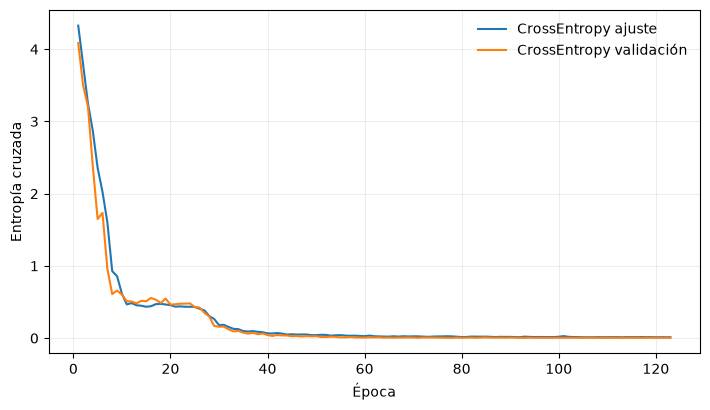

In [17]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(net.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=8, min_lr=1e-5
)

history = {"train_ce": [], "val_ce": [], "learning_rate": []}
best_val_loss = float("inf")
best_state = None
best_epoch = 0
steps_without_improvement = 0
start_time = time.time()

for epoch in range(NUM_EPOCHS):
    net.train()
    batch_losses = []
    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        _, output_spikes = net(inputs)
        logits = output_logits(output_spikes)
        loss = loss_fn(logits, targets)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(net.parameters(), max_norm=1.0)
        optimizer.step()
        batch_losses.append(float(loss.detach().cpu()))

    net.eval()
    with torch.no_grad():
        _, val_spikes = net(X_val.to(device))
        val_logits = output_logits(val_spikes)
        val_loss = float(loss_fn(val_logits, y_val.to(device)).cpu())

    scheduler.step(val_loss)
    train_ce = float(np.mean(batch_losses))
    history["train_ce"].append(train_ce)
    history["val_ce"].append(val_loss)
    history["learning_rate"].append(optimizer.param_groups[0]["lr"])

    if np.isfinite(val_loss) and val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        best_state = copy.deepcopy(net.state_dict())
        best_epoch = epoch + 1
        steps_without_improvement = 0
    else:
        steps_without_improvement += 1

    if epoch == 0 or (epoch+1) % 10 == 0:
        print(f"Época {epoch+1:03d}/{NUM_EPOCHS} | CE ajuste={train_ce:.4f} | CE val={val_loss:.4f} | escala={RATE_LOGIT_SCALE:g}")
    if steps_without_improvement >= PATIENCE:
        print(f"Parada temprana en época {epoch+1}; mejor época={best_epoch}.")
        break

if best_state is None:
    raise RuntimeError("No se obtuvo un estado válido; revisa la dinámica de spikes y los gradientes.")
net.load_state_dict(best_state)
train_time = time.time() - start_time
print(f"Tiempo: {train_time:.1f} s | mejor época: {best_epoch} | CE val: {best_val_loss:.5f}")

fig, ax = plt.subplots(figsize=(7.2,4.2))
ax.plot(np.arange(1,len(history["train_ce"])+1),history["train_ce"],label="CrossEntropy ajuste")
ax.plot(np.arange(1,len(history["val_ce"])+1),history["val_ce"],label="CrossEntropy validación")
ax.set(xlabel="Época",ylabel="Entropía cruzada")
ax.grid(alpha=0.22); ax.legend(frameon=False); fig.tight_layout(); plt.show()


## 8. Score y curva de fase

La probabilidad de fase 1 es el softmax aplicado a las tasas de las dos neuronas Alpha, multiplicadas por `RATE_LOGIT_SCALE=100`. La escala se usa también durante el entrenamiento con CrossEntropy. No modifica el orden de los ejemplos ni suaviza la gráfica. Se dibujan las 100 predicciones tal como las produce el modelo; pueden no tocar exactamente 0 y 1 si la QSNN no aprende suficiente separación entre las tasas.

--- Test reservado ---
accuracy          : 1.0000
precision_class1  : 1.0000
recall_class1     : 1.0000
f1_class1         : 1.0000
Matriz de confusión [real × predicha]:\n [[10  0]
 [ 0 10]]
Descensos locales del score: 8/99
Ejemplos sin spikes ocultos: 0.000


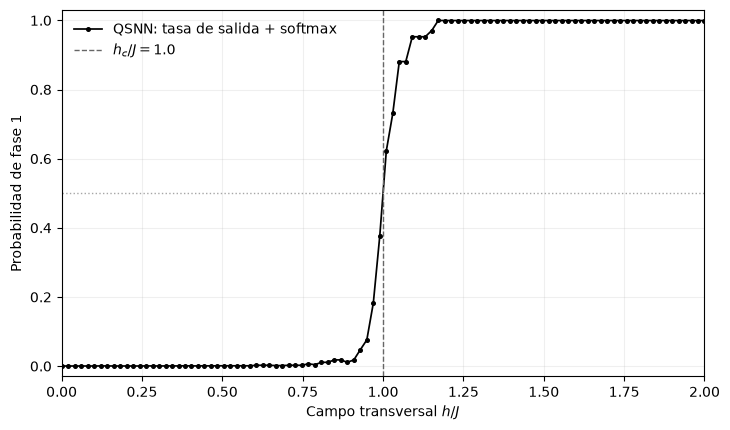

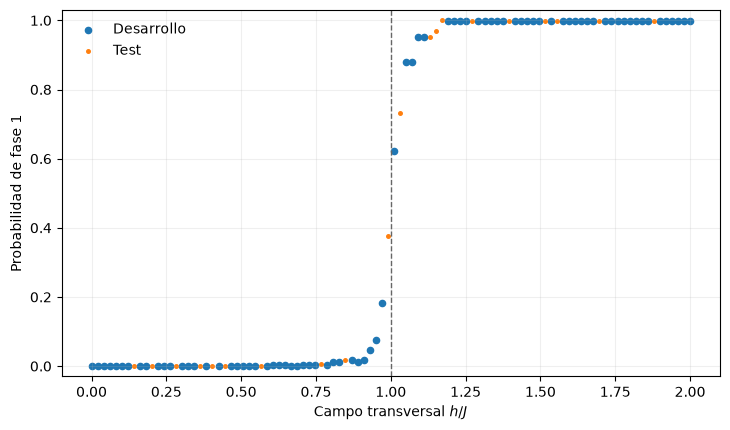

Resultados guardados en D:\UNI\tesis\Proyectos de Tesis\TESIS II\Tesis II codigos\results


In [18]:
net.eval()
with torch.no_grad():
    hidden_spikes, output_spikes = net(X.to(device))
    all_rates = output_rates(output_spikes).cpu().numpy()
    all_logits = RATE_LOGIT_SCALE * all_rates
    all_probabilities = torch.softmax(torch.as_tensor(all_logits), dim=1).numpy()
    all_predictions = all_logits.argmax(axis=1)
    output_spike_counts = output_spikes.sum(dim=0).cpu().numpy()
    total_hidden_spikes = hidden_spikes.sum(dim=(0,2)).cpu().numpy()

scores_class1 = all_probabilities[:,1]
test_pred = all_predictions[test_idx]
test_true = labels[test_idx]
metrics = {
    "accuracy": accuracy_score(test_true,test_pred),
    "precision_class1": precision_score(test_true,test_pred,zero_division=0),
    "recall_class1": recall_score(test_true,test_pred,zero_division=0),
    "f1_class1": f1_score(test_true,test_pred,zero_division=0),
}
conf = confusion_matrix(test_true,test_pred,labels=[0,1])
monotonic_violations = int(np.sum(np.diff(scores_class1[np.argsort(h_values)]) < -1e-6))
silent_fraction = float(np.mean(total_hidden_spikes == 0))

print("--- Test reservado ---")
for key,value in metrics.items(): print(f"{key:18s}: {value:.4f}")
print("Matriz de confusión [real × predicha]:\\n",conf)
print(f"Descensos locales del score: {monotonic_violations}/{len(scores_class1)-1}")
print(f"Ejemplos sin spikes ocultos: {silent_fraction:.3f}")

sort_idx = np.argsort(h_values/J)
fig,ax=plt.subplots(figsize=(7.4,4.4))
ax.plot(h_values[sort_idx]/J,scores_class1[sort_idx],marker="o",markersize=2.6,linewidth=1.25,color="black",label="QSNN: tasa de salida + softmax")
ax.axvline(H_C/J,color="0.4",linestyle="--",linewidth=1,label=fr"$h_c/J={H_C/J:.1f}$")
ax.axhline(0.5,color="0.65",linestyle=":",linewidth=1)
ax.set(xlabel=r"Campo transversal $h/J$",ylabel="Probabilidad de fase 1",xlim=(H_MIN/J,H_MAX/J),ylim=(-0.03,1.03))
ax.grid(alpha=0.2); ax.legend(frameon=False); fig.tight_layout(); plt.show()

fig,ax=plt.subplots(figsize=(7.4,4.4))
ax.scatter(h_values[dev_idx]/J,scores_class1[dev_idx],s=20,label="Desarrollo")
ax.scatter(h_values[test_idx]/J,scores_class1[test_idx],s=26,marker=".",label="Test")
ax.axvline(H_C/J,color="0.4",linestyle="--",linewidth=1)
ax.set(xlabel=r"Campo transversal $h/J$",ylabel="Probabilidad de fase 1",ylim=(-0.03,1.03))
ax.grid(alpha=0.2); ax.legend(frameon=False); fig.tight_layout(); plt.show()

results_df = pd.DataFrame({
    "h": h_values, "h_over_J": h_values/J, "label": labels,
    "predicted_label": all_predictions, "score_class_0": all_probabilities[:,0],
    "score_class_1": scores_class1, "rate_phase_0": all_rates[:,0],
    "rate_phase_1": all_rates[:,1], "spikes_phase_0": output_spike_counts[:,0],
    "spikes_phase_1": output_spike_counts[:,1], "total_hidden_spikes": total_hidden_spikes,
    "energy_vqe": energies, "energy_exact": exact_energies,
    "energy_error": energy_errors, "is_test": np.isin(np.arange(len(h_values)), test_idx)
}).sort_values("h").reset_index(drop=True)
results_df.to_csv(RESULTS_DIR / "qsnn_scores_dual_alpha.csv", index=False)
with open(RESULTS_DIR / "qsnn_metrics_dual_alpha.json", "w", encoding="utf-8") as f:
    json.dump({**metrics, "best_epoch": int(best_epoch), "train_time_s": float(train_time),
               "hidden_neurons": int(NUM_HIDDEN), "output_neurons": 2, "num_steps": int(NUM_STEPS),
               "num_parameters": int(num_parameters), "test_size": int(len(test_idx)),
               "validation_size": int(len(val_idx)), "monotonic_violations": monotonic_violations,
               "rate_logit_scale": RATE_LOGIT_SCALE, "loss": "cross_entropy_on_output_firing_rates"}, f, indent=2)
torch.save(net.state_dict(), RESULTS_DIR / "qsnn_dual_alpha_state_dict.pt")
print(f"Resultados guardados en {RESULTS_DIR.resolve()}")


## 9. Qué significa el resultado y límites

- La QSNN conserva sus dos neuronas Alpha finales. El CSV registra sus tasas y conteos de spikes; las probabilidades se calculan con softmax sobre esas tasas escaladas.
- No hay regularización de monotonía/curvatura ni suavizado posterior. La curva puede tener descensos locales; se reportan como diagnóstico, no se corrigen.
- 200 pasos dan resolución de tasa de 0.005. `RATE_LOGIT_SCALE=100` permite que una diferencia de tasa de aproximadamente 0.16 produzca una separación de logits cercana a 16, donde softmax suele dar scores casi 0 y 1. Esto calibra la confianza durante el entrenamiento; no inventa diferencias de disparo ni fuerza los extremos.
- La CrossEntropy compara las dos salidas con las etiquetas de fase. Las etiquetas son necesarias para este aprendizaje supervisado, pero no se pasan como entradas.
- El test tiene 20 estados y el resultado depende de la semilla. Repetir varias semillas es necesario para reportar un resultado robusto.
- La entrada es $|c_k|^2$, así que esta adaptación no accede a las fases complejas ni reproduce exactamente el clasificador cuántico del paper.

Se guardan `results/qsnn_scores_dual_alpha.csv`, `results/qsnn_metrics_dual_alpha.json` y `results/qsnn_dual_alpha_state_dict.pt`.

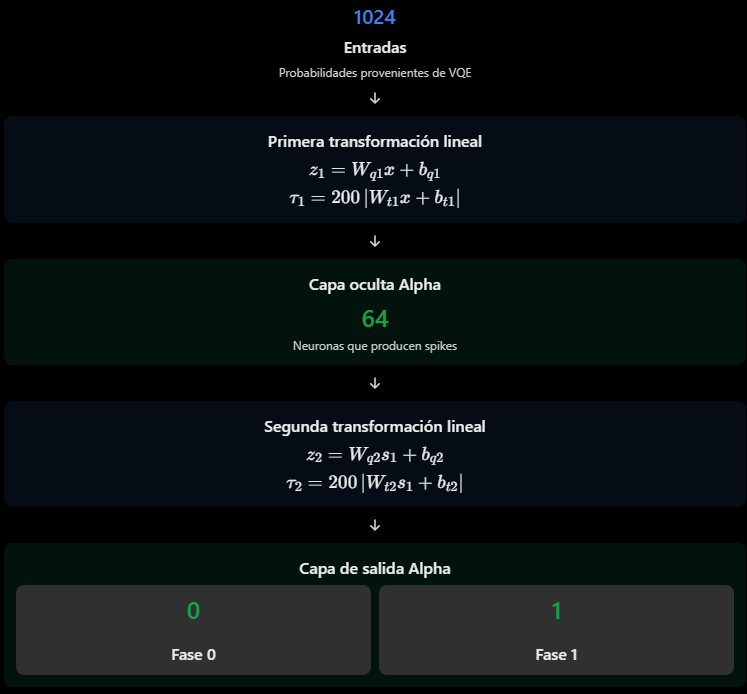